# Week 10: Data Preprocessing & Feature Engineering
## Project: Customer Churn Prediction

**Goal:** clean and transform customer data, engineer useful features, examine outliers, select features, and train a baseline churn classifier.

**Input file:** `churn_data.csv` (the CSV supplied with the task). It contains 500 rows and 9 columns. `Churn` is the target (1 = churn, 0 = retained).

**Important:** `CustomerID` is an identifier, so it is excluded from model features. All learned preprocessing steps are fitted on training data within a scikit-learn pipeline to reduce data leakage.


## 1. Setup and load the supplied dataset

In [1]:
# If needed, install dependencies from requirements.txt:
# pip install -r requirements.txt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, OrdinalEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, classification_report
from sklearn.feature_selection import mutual_info_classif

RANDOM_STATE = 42
df = pd.read_csv("churn_data.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))


Dataset shape: (500, 9)


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


\nData types:
CustomerID            str
Tenure              int64
MonthlyCharges      int64
TotalCharges        int64
Contract              str
PaymentMethod         str
PaperlessBilling      str
SeniorCitizen       int64
Churn               int64
dtype: object
\nMissing values:


,missing_count
CustomerID,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,0
PaperlessBilling,0
SeniorCitizen,0
Churn,0


## 2. Explore the data and target distribution

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,500,500,C00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,500.0,NaN,NaN,NaN,36.532,20.667057,1.0,19.0,37.0,54.0,71.0
MonthlyCharges,500.0,NaN,NaN,NaN,113.636,51.799903,20.0,67.0,115.0,158.0,199.0
TotalCharges,500.0,NaN,NaN,NaN,4237.882,2260.619837,159.0,2237.25,4182.5,6266.75,7992.0
Contract,500,3,One year,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,500,3,Credit Card,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaperlessBilling,500,2,No,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,500.0,NaN,NaN,NaN,0.498,0.500497,0.0,0.0,0.0,1.0,1.0
Churn,500.0,NaN,NaN,NaN,0.106,0.308146,0.0,0.0,0.0,0.0,1.0


Churn counts:


Churn
Retained    447
Churned      53
Name: count, dtype: int64

Overall churn rate: 10.6%


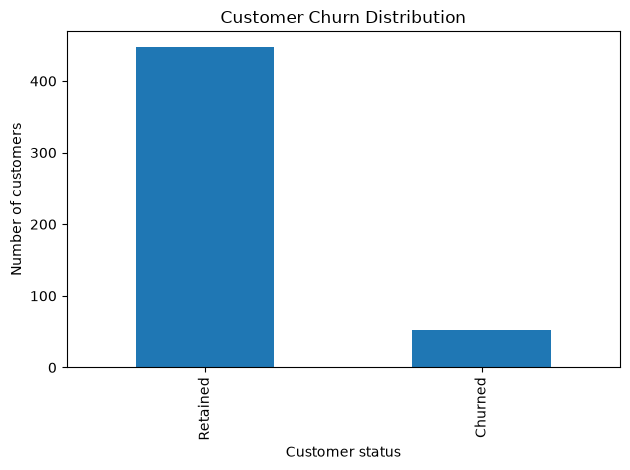

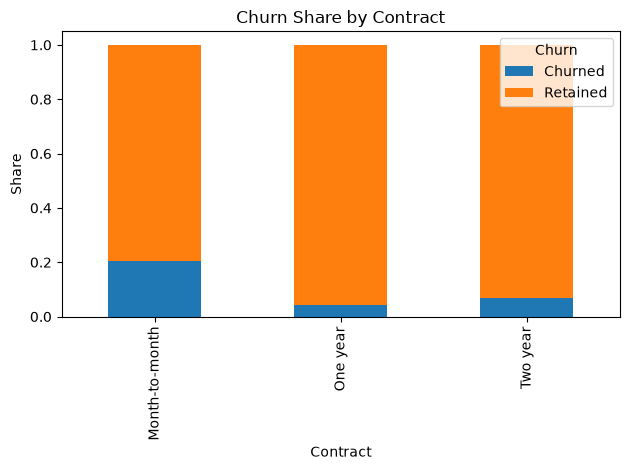

In [2]:
display(df.describe(include="all").T)
print("Churn counts:")
display(df["Churn"].value_counts().rename(index={0:"Retained", 1:"Churned"}))
print(f"Overall churn rate: {df['Churn'].mean():.1%}")

df["Churn"].map({0:"Retained", 1:"Churned"}).value_counts().reindex(["Retained","Churned"]).plot(kind="bar", title="Customer Churn Distribution")
plt.xlabel("Customer status"); plt.ylabel("Number of customers"); plt.tight_layout(); plt.show()

pd.crosstab(df["Contract"], df["Churn"].map({0:"Retained",1:"Churned"}), normalize="index").plot(kind="bar", stacked=True, title="Churn Share by Contract")
plt.xlabel("Contract"); plt.ylabel("Share"); plt.tight_layout(); plt.show()


## 3. Encoding categorical data — 3 methods demonstrated

1. **One-hot encoding:** appropriate for nominal input categories such as `PaymentMethod`.
2. **Ordinal encoding:** appropriate when a meaningful order is defined. We create ordered tenure bands (New, Established, Loyal).
3. **Label encoding:** used here for the binary target only. Avoid using label encoding for unordered input categories because it can imply a false ranking.


In [3]:
# Method 1: One-hot encoding demonstration
onehot_demo = pd.get_dummies(df[["Contract", "PaymentMethod", "PaperlessBilling"]], dummy_na=True)
display(onehot_demo.head())

# Method 2: Ordinal encoding for a derived, ordered tenure band
tenure_band = pd.cut(df["Tenure"], bins=[-1, 12, 36, np.inf],
                     labels=["New", "Established", "Loyal"])
ordinal_encoder = OrdinalEncoder(categories=[["New", "Established", "Loyal"]])
ordinal_values = ordinal_encoder.fit_transform(tenure_band.astype("object").to_frame())
print("Ordinal encoded tenure bands (first 10):", ordinal_values[:10].ravel())

# Method 3: Label encoding for target labels
target_encoder = LabelEncoder()
encoded_y = target_encoder.fit_transform(df["Churn"])
print("Target classes:", list(target_encoder.classes_))
print("Encoded target (first 10):", encoded_y[:10])


,Contract_Month-to-month,Contract_One year,Contract_Two year,Contract_nan,PaymentMethod_Bank Transfer,PaymentMethod_Credit Card,PaymentMethod_Electronic Check,PaymentMethod_nan,PaperlessBilling_No,PaperlessBilling_Yes,PaperlessBilling_nan
0,False,True,False,False,False,True,False,False,True,False,False
1,True,False,False,False,False,False,True,False,False,True,False
2,False,False,True,False,False,True,False,False,True,False,False
3,True,False,False,False,False,False,True,False,True,False,False
4,False,True,False,False,False,False,True,False,True,False,False


Ordinal encoded tenure bands (first 10): [0. 1. 1. 2. 1. 2. 2. 2. 2. 1.]
Target classes: [np.int64(0), np.int64(1)]
Encoded target (first 10): [0 0 0 0 0 0 0 0 0 0]


## 4. Feature engineering — create 7 new features

In [4]:
def add_features(data):
    out = data.copy()
    tenure = pd.to_numeric(out["Tenure"], errors="coerce")
    monthly = pd.to_numeric(out["MonthlyCharges"], errors="coerce")
    total = pd.to_numeric(out["TotalCharges"], errors="coerce")

    out["TenureYears"] = tenure / 12
    out["EstimatedLifetimeValue"] = total  # observed cumulative charges; proxy, not a forecast
    out["AverageMonthlySpend"] = total / tenure.replace(0, np.nan)
    out["MonthlyChargeToAverageRatio"] = monthly / (out["AverageMonthlySpend"].replace(0, np.nan))
    out["LongTenureFlag"] = (tenure >= 24).astype(int)
    out["MonthToMonthFlag"] = (out["Contract"].astype(str) == "Month-to-month").astype(int)
    out["ElectronicPaymentFlag"] = (out["PaymentMethod"].astype(str) == "Electronic check").astype(int)
    out["TenureBand"] = pd.cut(tenure, bins=[-1, 12, 36, np.inf],
                               labels=["New", "Established", "Loyal"]).astype("object")
    return out

featured = add_features(df)
new_features = ["TenureYears", "EstimatedLifetimeValue", "AverageMonthlySpend",
                "MonthlyChargeToAverageRatio", "LongTenureFlag", "MonthToMonthFlag",
                "ElectronicPaymentFlag", "TenureBand"]
display(featured[new_features + ["Churn"]].head())
print("New engineered features:", len(new_features))


,TenureYears,EstimatedLifetimeValue,AverageMonthlySpend,MonthlyChargeToAverageRatio,LongTenureFlag,MonthToMonthFlag,ElectronicPaymentFlag,TenureBand,Churn
0,0.500000,1540,256.666667,0.249351,0,0,0,New,0
1,1.750000,1753,83.476190,1.353679,0,1,0,Established,0
2,2.250000,1455,53.888889,0.575258,1,0,0,Established,0
3,4.416667,7150,134.905660,0.214965,1,1,0,Loyal,0
4,1.333333,1023,63.937500,2.893451,0,0,0,Established,0


New engineered features: 8


## 5. Outlier detection with IQR and Z-score

IQR flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Z-score flags values with absolute z-score greater than 3. Outliers are not automatically errors. We report them and retain records rather than deleting customers without business justification. Median imputation is included in the pipeline for missing numeric values.


In [5]:
numeric_for_outliers = ["Tenure", "MonthlyCharges", "TotalCharges"]
outlier_rows = []
for col in numeric_for_outliers:
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_count = int(((s < lower) | (s > upper)).sum())
    std = s.std(ddof=0)
    z_count = int((((s - s.mean()) / std).abs() > 3).sum()) if std else 0
    outlier_rows.append({"Feature": col, "IQR lower": lower, "IQR upper": upper,
                         "IQR outlier count": iqr_count, "Z-score outlier count": z_count})
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)


,Feature,IQR lower,IQR upper,IQR outlier count,Z-score outlier count
0,Tenure,-33.5,106.5,0,0
1,MonthlyCharges,-69.5,294.5,0,0
2,TotalCharges,-3807.0,12311.0,0,0


## 6. Compare Min-Max scaling and Standard scaling

In [6]:
scale_cols = ["Tenure", "MonthlyCharges", "TotalCharges"]
scale_demo = df[scale_cols].copy().fillna(df[scale_cols].median())
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()
minmax_values = minmax_scaler.fit_transform(scale_demo)
standard_values = standard_scaler.fit_transform(scale_demo)

print("Min-Max minimums:", np.round(minmax_values.min(axis=0), 3))
print("Min-Max maximums:", np.round(minmax_values.max(axis=0), 3))
print("StandardScaler means:", np.round(standard_values.mean(axis=0), 3))
print("StandardScaler standard deviations:", np.round(standard_values.std(axis=0), 3))
print("Min-Max scaling maps values to [0, 1]; StandardScaler centers around 0 with unit variance.")


Min-Max minimums: [0. 0. 0.]
Min-Max maximums: [1. 1. 1.]
StandardScaler means: [0. 0. 0.]
StandardScaler standard deviations: [1. 1. 1.]
Min-Max scaling maps values to [0, 1]; StandardScaler centers around 0 with unit variance.


## 7. Feature selection: correlation and mutual information

In [7]:
# Correlation for numeric features and binary target
numeric_features_view = featured.select_dtypes(include="number")
display(numeric_features_view.corr(numeric_only=True).round(2))

# Mutual information is a univariate ranking, not proof of causation.
mi_data = featured.drop(columns=["CustomerID"], errors="ignore").copy()
y_for_mi = mi_data["Churn"].astype(int)
X_for_mi = mi_data.drop(columns=["Churn"])
for col in X_for_mi.select_dtypes(include=["object", "category"]).columns:
    X_for_mi[col] = X_for_mi[col].astype("object").fillna("Unknown").astype("category").cat.codes
X_for_mi = X_for_mi.apply(pd.to_numeric, errors="coerce")
X_for_mi = X_for_mi.fillna(X_for_mi.median(numeric_only=True)).fillna(0)
mi_scores = mutual_info_classif(X_for_mi, y_for_mi, random_state=RANDOM_STATE)
mi_table = pd.DataFrame({"Feature": X_for_mi.columns, "MutualInformation": mi_scores}).sort_values("MutualInformation", ascending=False)
display(mi_table)


,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn,TenureYears,EstimatedLifetimeValue,AverageMonthlySpend,MonthlyChargeToAverageRatio,LongTenureFlag,MonthToMonthFlag,ElectronicPaymentFlag
Tenure,1.00,-0.06,-0.01,-0.04,-0.51,1.00,-0.01,-0.45,0.26,0.82,0.01,NaN
MonthlyCharges,-0.06,1.00,-0.04,-0.11,0.11,-0.06,-0.04,0.00,0.21,-0.01,-0.01,NaN
TotalCharges,-0.01,-0.04,1.00,0.02,0.00,-0.01,1.00,0.24,-0.40,0.00,-0.01,NaN
SeniorCitizen,-0.04,-0.11,0.02,1.00,-0.02,-0.04,0.02,-0.01,-0.08,-0.01,0.03,NaN
Churn,-0.51,0.11,0.00,-0.02,1.00,-0.51,0.00,0.40,-0.12,-0.52,0.23,NaN
TenureYears,1.00,-0.06,-0.01,-0.04,-0.51,1.00,-0.01,-0.45,0.26,0.82,0.01,NaN
EstimatedLifetimeValue,-0.01,-0.04,1.00,0.02,0.00,-0.01,1.00,0.24,-0.40,0.00,-0.01,NaN
AverageMonthlySpend,-0.45,0.00,0.24,-0.01,0.40,-0.45,0.24,1.00,-0.14,-0.42,0.04,NaN
MonthlyChargeToAverageRatio,0.26,0.21,-0.40,-0.08,-0.12,0.26,-0.40,-0.14,1.00,0.19,0.08,NaN
LongTenureFlag,0.82,-0.01,0.00,-0.01,-0.52,0.82,0.00,-0.42,0.19,1.00,-0.04,NaN


C:\Users\mkgmo\AppData\Local\Temp\ipykernel_22156\1321397614.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_for_mi.select_dtypes(include=["object", "category"]).columns:


,Feature,MutualInformation
14,TenureBand,0.245943
7,TenureYears,0.223091
0,Tenure,0.220336
11,LongTenureFlag,0.138804
9,AverageMonthlySpend,0.115275
10,MonthlyChargeToAverageRatio,0.090166
3,Contract,0.032871
12,MonthToMonthFlag,0.024214
1,MonthlyCharges,0.018086
4,PaymentMethod,0.001270


## 8. Complete preprocessing pipeline and baseline model

The pipeline imputes missing values, scales numeric features, one-hot encodes nominal categories, ordinal-encodes tenure band, and trains a Random Forest. `CustomerID` is excluded. The split is stratified so train/test churn proportions are similar.


,Score
Accuracy,0.980000
Precision,0.846154
Recall,1.000000
F1 score,0.916667


              precision    recall  f1-score   support

           0       1.00      0.98      0.99        89
           1       0.85      1.00      0.92        11

    accuracy                           0.98       100
   macro avg       0.92      0.99      0.95       100
weighted avg       0.98      0.98      0.98       100



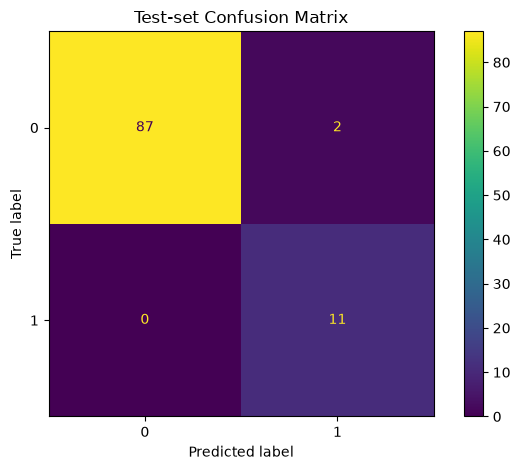

In [8]:
model_df = add_features(df)
X = model_df.drop(columns=["Churn", "CustomerID"], errors="ignore")
y = model_df["Churn"].astype(int)

numeric_features = ["Tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen",
                    "TenureYears", "EstimatedLifetimeValue", "AverageMonthlySpend",
                    "MonthlyChargeToAverageRatio", "LongTenureFlag",
                    "MonthToMonthFlag", "ElectronicPaymentFlag"]
nominal_features = ["Contract", "PaymentMethod", "PaperlessBilling"]
ordinal_features = ["TenureBand"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("nominal", nominal_pipeline, nominal_features),
    ("ordinal", ordinal_pipeline, ordinal_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE,
                                     class_weight="balanced"))
])
pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1 score": f1_score(y_test, pred, zero_division=0)
}
display(pd.DataFrame([metrics]).T.rename(columns={0:"Score"}))
print(classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Test-set Confusion Matrix"); plt.tight_layout(); plt.show()


## 9. Validation and simple test cases

In [9]:
# Test 1: pipeline returns one prediction per test row
assert len(pred) == len(X_test), "Prediction count does not match test row count"

# Test 2: predictions are valid binary labels
assert set(np.unique(pred)).issubset({0, 1}), "Unexpected prediction labels"

# Test 3: preprocessing can handle an unseen category because OneHotEncoder uses handle_unknown='ignore'
sample = X_test.iloc[[0]].copy()
sample["PaymentMethod"] = "New unseen payment method"
sample_prediction = pipeline.predict(sample)
assert len(sample_prediction) == 1
print("All 3 validation checks passed.")
print("Sample prediction (1 = likely churn, 0 = likely retained):", int(sample_prediction[0]))


All 3 validation checks passed.
Sample prediction (1 = likely churn, 0 = likely retained): 0


## 10. Interpretation and limitations

- This is a baseline model intended to demonstrate preprocessing and feature engineering, not a production-ready churn system.
- Accuracy alone can hide poor performance on the minority class; inspect precision, recall, F1 and the confusion matrix.
- `EstimatedLifetimeValue` is the observed `TotalCharges` renamed as a descriptive proxy, not a future revenue forecast.
- Feature importance/correlation do not establish causation.
- Validate on fresh data, monitor performance over time, and consider business costs of false positives and false negatives before deployment.
